## **1. Finding real dataset, loading it on Colab, and visualizing it.**

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
import pandas as pd
import numpy as np

df=pd.read_csv('/content/drive/MyDrive/DataScienceTutorial/Tutorial3/iris-data.csv')
df

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


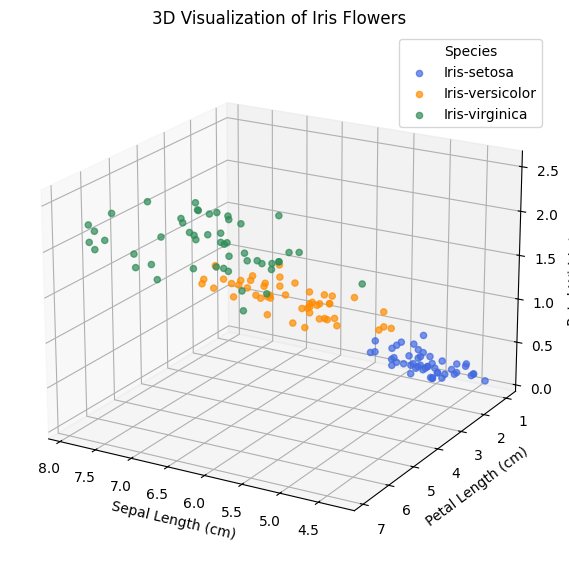

In [38]:
import matplotlib.pyplot as plt

figInteractive = plt.figure(figsize=(9, 7))
ax = figInteractive.add_subplot(111, projection='3d')

colors = {
    'Iris-setosa': 'royalblue',
    'Iris-versicolor': 'darkorange',
    'Iris-virginica': 'seagreen'
}

for species, color in colors.items():
    subset = df[df['class'] == species]

    ax.scatter(
        subset['sepal length'],
        subset['petal length'],
        subset['petal width'],
        label=species,
        color=color,
        alpha=0.7
    )

ax.set_title('3D Visualization of Iris Flowers')
ax.set_xlabel('Sepal Length (cm)')
ax.set_ylabel('Petal Length (cm)')
ax.set_zlabel('Petal Width (cm)')
ax.legend(title='Species')
ax.view_init(elev=20, azim=120)


plt.show()

In [37]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='sepal length',
    y='petal length',
    z='petal width',
    color='class',
    title='Interactive 3D Iris Visualization',
    labels={
        'sepal length': 'Sepal Length (cm)',
        'petal length': 'Petal Length (cm)',
        'petal width': 'Petal Width (cm)',
        'class': 'Species'
    }
)

fig.show()

##2. Evalute is the data good or not. Does it have enough samples?
##**ANSWER: The dataset is considered decent as it has a significant amount of samples.**

## 3. How many features does it have? Is it enough?
## **ANSWER: The dataset has 4 features and they are enough for predicting the iris species.**

In [26]:
df.shape # Value contains (x, y) where x is the number of row and y refers the number of column, which is 5 columns.

(150, 5)

## 4. How many samples/observation does it have? Is it enough?
## **ANSWER: The dataset has enough samples with the total of 150.**

## 5. What are the datatypes does the dataset consist of?
## **Feature columns contain continuous quantitative data values and the target column consists of nominal qualitative values.**

## 6. How many columns have null values? If yes, which column, which rows?
## **There is no null values inside the dataset. But in order to identify one and its location, the following code helps doing so.**

In [27]:
if df.isnull().values.any(): # Condition -> nulls exist in columns
    print("⚠️ Nulls detected! Locating them now...")
    # Look for exact locations
    null_locations = [(idx, col) for col in df.columns for idx in df[df[col].isnull()].index]
    print("Null locations:", null_locations)

    # Output: Null locations: []

else: # Condition - no null in any columns
    print("✅ Clean dataset! No null values found.")


✅ Clean dataset! No null values found.


## 7. Which column is the feature, which is the target output?
## **In this case, the features are sepal length, sepal width, petal length, and petal width, while the target output is class.**

In [28]:
df

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


## 8. Does it have missing values? If yes, which column, which row.
## **The dataset does not have any missing values.**

In [29]:
print(df.isnull().sum()); # Check the num of missing values in each column

sepal length    0
sepal width     0
petal length    0
petal width     0
class           0
dtype: int64
